# Association Rule Mining for Urban Taxi Demand

**Workstream:** association-rule-mining | **Milestone:** Review 3  

This notebook discovers, validates, and prunes operational association rules relating spatio-temporal and weather factors to NYC taxi demand levels (`demand=High`, `demand=Medium`, `demand=Low`).

### Workflow Architecture

| Section | Analytical Focus | Core Deliverables |
|---|---|---|
| **1. Setup & Environment** | Libraries, path resolution, and design configuration | Reproducible environment configuration |
| **2. Transaction Data Overview** | Matrix shape, catalog distribution, and demand prevalence | Verification of one-hot binarised transactions |
| **3. Rule Mining Engine** | Apriori and FP-Growth rule generation | Unconstrained candidate demand rules |
| **4. Holdout Validation** | Out-of-sample evaluation on unseen test split | Metric stability filtering (Test count $\ge 100$) |
| **5. Redundancy Elimination** | Proper subset pruning ($A_1 \subset A_2, \text{conf}(R_2) \le \text{conf}(R_1)$) | **160 Clean Non-Redundant Rules** + Pruning Audit Log |
| **6. Pruned Rules Visualisations** | Evaluation strictly on pruned portfolio | **Metric Scatter, Parity Plot, Factor Heatmap, Top Rules** |
| **7. Pruning Mechanics & Dropped Features** | Feature-level attrition analysis | **Waterfall Funnel & Dropped Features Attribution** |
| **8. Algorithm Scalability Benchmarks** | Computational performance comparison | **Runtime & Rule Count Scalability (2-Panel Figure)** |
| **9. Artefact Export** | Structured CSV storage for downstream modelling | Final curated rule tables in `data/processed/arm_findings/` |

> **Methodological Note:** Rules are mined exclusively on the training partition (September 2025 - January 2026). The holdout test partition (January 2026 - February 2026) is strictly reserved to evaluate out-of-sample generalisation.

---
## 1. Setup & Environment

We initialise required scientific packages, dynamically resolve project paths, and establish standard visualisation styling.

In [1]:
from pathlib import Path
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

# Dynamically resolve project root whether running from scripts/ or repository root
ROOT = Path('.') if Path('data').exists() else Path('..')
DATA = ROOT / 'data'
PROCESSED = DATA / 'processed'
ARM_DIR = PROCESSED / 'association_rules'
FINDINGS_DIR = PROCESSED / 'arm_findings'
SCRIPTS = ROOT / 'scripts'

FINDINGS_DIR.mkdir(parents=True, exist_ok=True)

# Establish consistent corporate visual styling
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Import data loader from scripts/
sys.path.insert(0, str(SCRIPTS))
from association_rule_data_preparation import load_transactions

---
## 2. Load Prepared Transactions

Each row in the transaction matrix represents a discrete zone-hour observation. Every observation contains exactly one active item from each binarised feature family.

In [2]:
# Load pre-split binarised matrices and metadata
X_train, train_meta = load_transactions('train', output_dir=ARM_DIR)
X_test, test_meta = load_transactions('test', output_dir=ARM_DIR)

print(f'Training matrix : {X_train.shape[0]:,} rows x {X_train.shape[1]} items')
print(f'Holdout matrix  : {X_test.shape[0]:,} rows x {X_test.shape[1]} items')

# Integrity assertion checks
assert X_train.index.equals(train_meta.index), 'Training matrix index mismatch!'
assert X_test.index.equals(test_meta.index), 'Test matrix index mismatch!'
assert X_train.columns.equals(X_test.columns), 'Feature column mismatch between splits!'

Training matrix : 320,544 rows x 24 items
Holdout matrix  : 80,256 rows x 24 items


In [3]:
# Verify that each transaction contains exactly one active category per feature family
train_items_per_row = pd.Series(X_train.sparse.to_coo().tocsr().getnnz(axis=1))
test_items_per_row = pd.Series(X_test.sparse.to_coo().tocsr().getnnz(axis=1))

print('Items per transaction distribution (Train):')
print(train_items_per_row.value_counts())
print('Items per transaction distribution (Test):')
print(test_items_per_row.value_counts())

Items per transaction distribution (Train):
8    320544
Name: count, dtype: int64
Items per transaction distribution (Test):
8    80256
Name: count, dtype: int64


In [4]:
# Summarise item catalog support and feature families
train_support = pd.Series(np.asarray(X_train.mean(axis=0)).ravel(), index=X_train.columns)
test_support = pd.Series(np.asarray(X_test.mean(axis=0)).ravel(), index=X_test.columns)

item_catalog = pd.DataFrame({
    'item': X_train.columns,
    'feature_family': [c.split('=')[0] for c in X_train.columns],
    'train_support': train_support.values,
    'test_support': test_support.values,
    'support_difference': (test_support - train_support).values
}).sort_values('train_support', ascending=False).reset_index(drop=True)

# Glimpse first 5 items
item_catalog.head(5)

,item,feature_family,train_support,test_support,support_difference
0,time_band=late_night,time_band,1,1,0
1,time_band=early_morning,time_band,1,1,0
2,time_band=am_rush,time_band,1,1,0
3,time_band=midday,time_band,1,1,0
4,time_band=pm_rush,time_band,1,1,0


In [5]:
# Confirm baseline consequent prevalence
demand_items = [c for c in X_train.columns if c.startswith('demand=')]
demand_prevalence = item_catalog[item_catalog['item'].isin(demand_items)].copy()
demand_prevalence

,item,feature_family,train_support,test_support,support_difference
20,demand=Low,demand,1,1,0
21,demand=Medium,demand,1,1,0
22,demand=High,demand,1,1,0


---
## 3. Association Rule Mining Engine

We evaluate both **Apriori** and **FP-Growth** across multiple minimum support thresholds (`0.05`, `0.01`, `0.005`) with minimum confidence set to `0.50`.

Rules are strictly filtered to demand-consequent rules (`consequents \in {demand=High, demand=Medium, demand=Low}`) with single-item consequents.

In [6]:
MIN_SUPPORT_GRID = [0.05, 0.01, 0.005]
MIN_CONFIDENCE = 0.50
MIN_LIFT = 1.20

def filter_demand_rules(rules, demand_item_set):
    if rules.empty:
        return pd.DataFrame()
    is_single_consequent = rules['consequents'].apply(lambda s: len(s) == 1)
    predicts_demand = rules['consequents'].apply(lambda s: bool(set(s).intersection(demand_item_set)))
    demand_rules = rules[is_single_consequent & predicts_demand].copy()
    return demand_rules

def format_rules(df):
    if df.empty:
        return df
    formatted = df.copy()
    formatted['antecedent_text'] = formatted['antecedents'].apply(lambda s: ', '.join(sorted(s)))
    formatted['consequent_text'] = formatted['consequents'].apply(lambda s: ', '.join(sorted(s)))
    formatted['rule_length'] = formatted['antecedents'].apply(len) + formatted['consequents'].apply(len)
    return formatted

In [7]:
# Mine frequent itemsets and rules using Apriori
apriori_results = []
apriori_rule_tables = []

for min_support in MIN_SUPPORT_GRID:
    t0 = time.perf_counter()
    frequent_itemsets = apriori(X_train, min_support=min_support, use_colnames=True)
    runtime = time.perf_counter() - t0
    
    apriori_results.append({
        'algorithm': 'Apriori',
        'min_support': min_support,
        'n_itemsets': len(frequent_itemsets),
        'runtime_seconds': runtime,
        'frequent_itemsets': frequent_itemsets
    })
    
    rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=MIN_CONFIDENCE)
    demand_rules = filter_demand_rules(rules, set(demand_items))
    demand_rules['algorithm'] = 'Apriori'
    demand_rules['min_support_threshold'] = min_support
    apriori_rule_tables.append(demand_rules)
    
    print(f'Apriori | support={min_support} | itemsets={len(frequent_itemsets):,} | demand rules={len(demand_rules):,} | time={runtime:.2f}s')

apriori_rules_all = pd.concat(apriori_rule_tables, ignore_index=True)
apriori_rules_all = format_rules(apriori_rules_all)
apriori_rules_all.head(5)

Apriori | support=0.05 | itemsets=1,167 | demand rules=87 | time=4.53s
Apriori | support=0.01 | itemsets=4,707 | demand rules=628 | time=20.08s
Apriori | support=0.005 | itemsets=6,719 | demand rules=897 | time=28.54s


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski,algorithm,min_support_threshold,antecedent_text,consequent_text,rule_length
0,(time_band=late_night),(demand=Low),0.209045,0.375736,0.163940,0.784235,2.087195,1.0,0.085394,2.893254,0.658556,0.389554,0.654368,0.610276,Apriori,0.05,time_band=late_night,demand=Low,2
1,(time_band=early_morning),(demand=Low),0.083258,0.375736,0.060859,0.730965,1.945421,1.0,0.029576,2.320383,0.530108,0.152860,0.569037,0.446469,Apriori,0.05,time_band=early_morning,demand=Low,2
2,(time_band=pm_rush),(demand=High),0.166517,0.305272,0.091058,0.546838,1.791314,1.0,0.040225,1.533067,0.530006,0.239166,0.347713,0.422561,Apriori,0.05,time_band=pm_rush,demand=High,2
3,"(time_band=late_night, day_type=weekday)",(demand=Low),0.149745,0.375736,0.129938,0.867729,2.309410,1.0,0.073674,4.719587,0.666846,0.328506,0.788117,0.606776,Apriori,0.05,"day_type=weekday, time_band=late_night",demand=Low,3
4,"(holiday=regular, time_band=late_night)",(demand=Low),0.200060,0.375736,0.157747,0.788501,2.098550,1.0,0.082578,2.951617,0.654399,0.377342,0.661203,0.604168,Apriori,0.05,"holiday=regular, time_band=late_night",demand=Low,3


In [8]:
# Mine frequent itemsets and rules using FP-Growth
fpgrowth_results = []
fpgrowth_rule_tables = []

for min_support in MIN_SUPPORT_GRID:
    t0 = time.perf_counter()
    frequent_itemsets = fpgrowth(X_train, min_support=min_support, use_colnames=True)
    runtime = time.perf_counter() - t0
    
    fpgrowth_results.append({
        'algorithm': 'FP-Growth',
        'min_support': min_support,
        'n_itemsets': len(frequent_itemsets),
        'runtime_seconds': runtime,
        'frequent_itemsets': frequent_itemsets
    })
    
    rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=MIN_CONFIDENCE)
    demand_rules = filter_demand_rules(rules, set(demand_items))
    demand_rules['algorithm'] = 'FP-Growth'
    demand_rules['min_support_threshold'] = min_support
    fpgrowth_rule_tables.append(demand_rules)
    
    print(f'FP-Growth | support={min_support} | itemsets={len(frequent_itemsets):,} | demand rules={len(demand_rules):,} | time={runtime:.2f}s')

fpgrowth_rules_all = pd.concat(fpgrowth_rule_tables, ignore_index=True)
fpgrowth_rules_all = format_rules(fpgrowth_rules_all)
fpgrowth_rules_all.head(5)

FP-Growth | support=0.05 | itemsets=1,167 | demand rules=87 | time=1.33s
FP-Growth | support=0.01 | itemsets=4,707 | demand rules=628 | time=1.38s
FP-Growth | support=0.005 | itemsets=6,719 | demand rules=897 | time=1.31s


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski,algorithm,min_support_threshold,antecedent_text,consequent_text,rule_length
0,(time_band=late_night),(demand=Low),0.209045,0.375736,0.163940,0.784235,2.087195,1.0,0.085394,2.893254,0.658556,0.389554,0.654368,0.610276,FP-Growth,0.05,time_band=late_night,demand=Low,2
1,"(snow=no, time_band=late_night)",(demand=Low),0.206100,0.375736,0.162184,0.786919,2.094338,1.0,0.084745,2.929698,0.658171,0.386472,0.658668,0.609281,FP-Growth,0.05,"snow=no, time_band=late_night",demand=Low,3
2,"(holiday=regular, time_band=late_night)",(demand=Low),0.200060,0.375736,0.157747,0.788501,2.098550,1.0,0.082578,2.951617,0.654399,0.377342,0.661203,0.604168,FP-Growth,0.05,"holiday=regular, time_band=late_night",demand=Low,3
3,"(time_band=late_night, rain=no)",(demand=Low),0.200219,0.375736,0.157676,0.787516,2.095928,1.0,0.082446,2.937935,0.653784,0.376962,0.659625,0.603580,FP-Growth,0.05,"rain=no, time_band=late_night",demand=Low,3
4,"(holiday=regular, snow=no, time_band=late_night)",(demand=Low),0.197115,0.375736,0.155991,0.791371,2.106188,1.0,0.081928,2.992223,0.654152,0.374205,0.665800,0.603266,FP-Growth,0.05,"holiday=regular, snow=no, time_band=late_night",demand=Low,4


In [9]:
# Select FP-Growth rules at min_support=0.005 for holdout evaluation
FINAL_MIN_SUPPORT = 0.005
final_rules = fpgrowth_rules_all[fpgrowth_rules_all['min_support_threshold'].eq(FINAL_MIN_SUPPORT)].copy()
final_rules = final_rules.sort_values(['lift', 'confidence', 'support'], ascending=[False, False, False]).reset_index(drop=True)

print(f'Selected candidate rules: {len(final_rules):,}')
final_rules[['antecedent_text', 'consequent_text', 'support', 'confidence', 'lift', 'leverage', 'conviction']].head(5)

Selected candidate rules: 897


,antecedent_text,consequent_text,support,confidence,lift,leverage,conviction
0,"day_type=weekend, rain=no, time_band=early_morning, zone_cluster=daytime",demand=Low,0.012295,0.937887,2.496131,0.007369,10.050407
1,"day_type=weekend, holiday=regular, rain=no, time_band=early_morning, zone_cluster=daytime",demand=Low,0.012295,0.937887,2.496131,0.007369,10.050407
2,"day_type=weekend, rain=no, snow=no, time_band=early_morning, zone_cluster=daytime",demand=Low,0.012295,0.937887,2.496131,0.007369,10.050407
3,"day_type=weekend, holiday=regular, rain=no, snow=no, time_band=early_morning, zone_cluster=daytime",demand=Low,0.012295,0.937887,2.496131,0.007369,10.050407
4,"day_type=weekend, snow=no, time_band=early_morning, zone_cluster=daytime",demand=Low,0.012504,0.936667,2.492886,0.007488,9.856917


---
## 4. Holdout Test-Period Validation & Stability Filtering

Mined candidate rules are evaluated against the unseen holdout test matrix (`80,256` observations from January 2026 - February 2026).

A rule is categorised as **Holdout-Stable** if it satisfies three operational criteria on unseen data:
1. $\text{Test Antecedent Count} \ge 100$ (prevents seasonal sample starvation)
2. $\text{Test Confidence} \ge 0.50$ (maintains decision reliability)
3. $\text{Test Lift} \ge 1.20$ (confirms genuine lift above independent baseline)

In [10]:
# Fast holdout matrix evaluation utilising CSR caching
def evaluate_rules_on_matrix(rules, X):
    records = []
    n_rows = X.shape[0]
    X_csr = X.sparse.to_coo().tocsr()
    col_index = {item: idx for idx, item in enumerate(X.columns)}
    cache = {}
    
    def get_mask(items):
        key = frozenset(items)
        if key not in cache:
            cols = [col_index[item] for item in items]
            cache[key] = np.asarray(X_csr[:, cols].getnnz(axis=1)).ravel() == len(cols)
        return cache[key]
    
    for idx, row in rules.iterrows():
        antecedents = list(row['antecedents'])
        consequents = list(row['consequents'])
        both_items = antecedents + consequents
        
        antecedent_mask = get_mask(antecedents)
        consequent_mask = get_mask(consequents)
        both_mask = get_mask(both_items)
        
        antecedent_count = antecedent_mask.sum()
        consequent_count = consequent_mask.sum()
        rule_count = both_mask.sum()
        
        antecedent_support = antecedent_count / n_rows
        consequent_support = consequent_count / n_rows
        support = rule_count / n_rows
        
        confidence = support / antecedent_support if antecedent_support > 0 else np.nan
        lift = confidence / consequent_support if consequent_support > 0 else np.nan
        
        records.append({
            'rule_index': idx,
            'test_support': support,
            'test_antecedent_support': antecedent_support,
            'test_consequent_support': consequent_support,
            'test_confidence': confidence,
            'test_lift': lift,
            'test_antecedent_count': int(antecedent_count),
            'test_rule_count': int(rule_count)
        })
    return pd.DataFrame(records)

test_metrics = evaluate_rules_on_matrix(final_rules, X_test)
final_rules_tested = final_rules.reset_index(drop=True).join(test_metrics.set_index('rule_index'), how='left')
final_rules_tested['confidence_change'] = final_rules_tested['test_confidence'] - final_rules_tested['confidence']
final_rules_tested['lift_change'] = final_rules_tested['test_lift'] - final_rules_tested['lift']

final_rules_tested[['antecedent_text', 'consequent_text', 'confidence', 'test_confidence', 'lift', 'test_lift', 'test_antecedent_count']].head(5)

,antecedent_text,consequent_text,confidence,test_confidence,lift,test_lift,test_antecedent_count
0,"day_type=weekend, rain=no, time_band=early_morning, zone_cluster=daytime",demand=Low,0.937887,0.942752,2.496131,2.266196,1083
1,"day_type=weekend, holiday=regular, rain=no, time_band=early_morning, zone_cluster=daytime",demand=Low,0.937887,0.942752,2.496131,2.266196,1083
2,"day_type=weekend, rain=no, snow=no, time_band=early_morning, zone_cluster=daytime",demand=Low,0.937887,0.942752,2.496131,2.266196,1083
3,"day_type=weekend, holiday=regular, rain=no, snow=no, time_band=early_morning, zone_cluster=daytime",demand=Low,0.937887,0.942752,2.496131,2.266196,1083
4,"day_type=weekend, snow=no, time_band=early_morning, zone_cluster=daytime",demand=Low,0.936667,0.942752,2.492886,2.266196,1083


In [11]:
# Filter candidate rules down to holdout-stable portfolio
stable_rules = final_rules_tested[
    final_rules_tested['test_antecedent_count'].ge(100) &
    final_rules_tested['test_confidence'].ge(MIN_CONFIDENCE) &
    final_rules_tested['test_lift'].ge(MIN_LIFT)
].copy()

stable_rules = stable_rules.sort_values(['test_lift', 'test_confidence', 'test_support'], ascending=[False, False, False]).reset_index(drop=True)
print(f'Holdout-stable rules retained: {len(stable_rules):,} (from {len(final_rules):,} candidates)')

stable_rules[['antecedent_text', 'consequent_text', 'support', 'confidence', 'lift', 'test_support', 'test_confidence', 'test_lift', 'test_antecedent_count']].head(5)

Holdout-stable rules retained: 632 (from 897 candidates)


,antecedent_text,consequent_text,support,confidence,lift,test_support,test_confidence,test_lift,test_antecedent_count
0,"day_type=weekday, holiday=regular, rain=no, temperature=lower, time_band=am_rush, zone_cluster=morning_commute",demand=High,0.006055,0.670466,2.196294,0.017432,0.767838,2.842940,1822
1,"day_type=weekday, holiday=regular, rain=no, snow=no, temperature=lower, time_band=am_rush, zone_cluster=morning_commute",demand=High,0.006055,0.670466,2.196294,0.017432,0.767838,2.842940,1822
2,"day_type=weekday, holiday=regular, snow=no, temperature=lower, time_band=am_rush, zone_cluster=morning_commute",demand=High,0.006062,0.670462,2.196281,0.018142,0.762703,2.823929,1909
3,"day_type=weekday, holiday=regular, rain=no, time_band=am_rush, zone_cluster=morning_commute",demand=High,0.015527,0.640541,2.098264,0.017768,0.762567,2.823425,1870
4,"day_type=weekday, holiday=regular, rain=no, snow=no, time_band=am_rush, zone_cluster=morning_commute",demand=High,0.015527,0.640541,2.098264,0.017768,0.762567,2.823425,1870


In [12]:
# Aggregate performance by consequent class
stable_summary = stable_rules.groupby('consequent_text', as_index=False).agg(
    n_rules=('consequent_text', 'size'),
    mean_test_confidence=('test_confidence', 'mean'),
    mean_test_lift=('test_lift', 'mean'),
    max_test_lift=('test_lift', 'max')
)
stable_summary

,consequent_text,n_rules,mean_test_confidence,mean_test_lift,max_test_lift
0,demand=High,174,0.613479,2.271422,2.842940
1,demand=Low,416,0.766874,1.843419,2.346424
2,demand=Medium,42,0.580112,1.848031,1.951710


---
## 5. Redundant Rule Elimination

In transactional association mining, frequent itemset algorithms generate numerous combinatorial permutations. A rule $R_2: A_2 \implies C$ is formally defined as **redundant** with respect to a more general rule $R_1: A_1 \implies C$ if:

1. Both rules predict the identical consequent $C$.
2. The antecedent $A_1$ is a strict proper subset of $A_2$ ($A_1 \subset A_2$).
3. The specific rule $R_2$ yields no improvement in confidence over $R_1$ (i.e. $\text{confidence}(R_2) \le \text{confidence}(R_1)$).

Tacking on baseline attributes (e.g., `snow=no`, `holiday=regular`, or `rain=no`) without increasing predictive strength produces redundant noise. Pruning these rules enforces **parsimony** and isolates the true operational drivers.

In [13]:
def to_set(x):
    if isinstance(x, (set, frozenset)):
        return set(x)
    if isinstance(x, str) and x.startswith('frozenset('):
        import ast
        return ast.literal_eval(x[10:-1])
    if isinstance(x, str):
        return set(s.strip() for s in x.split(','))
    return set(x)

def find_redundant_rules(rules_df, min_confidence_gain=0.0):
    rules = rules_df.copy().reset_index(drop=True)
    rules['ant_set'] = rules['antecedents'].apply(to_set)
    records = [{
        'index': idx,
        'ant': r['ant_set'],
        'con': r['consequent_text'],
        'conf': r['confidence'],
        'test_conf': r['test_confidence'],
        'lift': r['lift'],
        'test_lift': r['test_lift']
    } for idx, r in rules.iterrows()]
    
    redundant_indices, redundant_pairs = set(), []
    by_con = {}
    for r in records:
        by_con.setdefault(r['con'], []).append(r)
        
    for con, rlist in by_con.items():
        for r2 in rlist:
            for r1 in rlist:
                if r1['index'] == r2['index']:
                    continue
                if r1['ant'] < r2['ant']:  # Strict proper subset
                    if r2['conf'] <= r1['conf'] + min_confidence_gain:
                        redundant_indices.add(r2['index'])
                        redundant_pairs.append({
                            'redundant_index': r2['index'],
                            'subsumed_by_index': r1['index'],
                            'redundant_rule': rules.loc[r2['index'], 'antecedent_text'],
                            'general_rule': rules.loc[r1['index'], 'antecedent_text'],
                            'consequent': con,
                            'redundant_conf': r2['conf'],
                            'general_conf': r1['conf'],
                            'redundant_test_lift': r2['test_lift'],
                            'general_test_lift': r1['test_lift']
                        })
                        break
    
    non_redundant_df = (
        rules.drop(index=list(redundant_indices))
        .drop(columns=['ant_set'])
        .sort_values(['test_lift', 'test_confidence', 'test_support'], ascending=[False, False, False])
        .reset_index(drop=True)
    )
    return non_redundant_df, pd.DataFrame(redundant_pairs)

stable_rules_non_redundant, redundant_log = find_redundant_rules(stable_rules, min_confidence_gain=0.0)

print(f'Holdout-stable rules before pruning : {len(stable_rules):,}')
print(f'Redundant rules identified & pruned : {len(redundant_log):,}')
print(f'Clean non-redundant portfolio       : {len(stable_rules_non_redundant):,}')

Holdout-stable rules before pruning : 632
Redundant rules identified & pruned : 480
Clean non-redundant portfolio       : 152


In [14]:
# Glimpse audited redundant pairs
print('Sample Redundant Rule Pairs (Subsumed by General Rules):')
display(redundant_log[['redundant_rule', 'general_rule', 'consequent', 'redundant_conf', 'general_conf']].head(5))

# Glimpse final non-redundant rules
print('Sample Clean Non-Redundant Rules:')
stable_rules_non_redundant[['antecedent_text', 'consequent_text', 'support', 'confidence', 'test_confidence', 'test_lift']].head(5)

Sample Redundant Rule Pairs (Subsumed by General Rules):
                                      redundant_rule  ... general_conf
0  day_type=weekday, holiday=regular, rain=no, te...  ...     0.675394
1  day_type=weekday, holiday=regular, rain=no, sn...  ...     0.670466
2  day_type=weekday, holiday=regular, snow=no, te...  ...     0.675394
3  day_type=weekday, holiday=regular, rain=no, ti...  ...     0.649792
4  day_type=weekday, holiday=regular, rain=no, sn...  ...     0.640541

[5 rows x 5 columns]
Sample Clean Non-Redundant Rules:


,antecedent_text,consequent_text,support,confidence,test_confidence,test_lift
0,"day_type=weekday, holiday=regular, temperature=lower, time_band=am_rush, zone_cluster=morning_commute",demand=High,0.006277,0.675394,0.733072,2.714218
1,"day_type=weekday, holiday=regular, time_band=am_rush, zone_cluster=morning_commute",demand=High,0.016578,0.649792,0.728927,2.698873
2,"day_type=weekday, temperature=lower, time_band=am_rush, zone_cluster=morning_commute",demand=High,0.006523,0.627363,0.706824,2.617034
3,"day_type=weekday, time_band=am_rush, zone_cluster=morning_commute",demand=High,0.016896,0.622529,0.703448,2.604537
4,"day_type=weekday, holiday=regular, snow=no, time_band=pm_rush, zone_cluster=daytime",demand=High,0.048355,0.729034,0.669225,2.477825


---
## 6. Pruning Mechanics & Dropped Feature Attribution

We analyse how candidate rules were filtered across each pipeline stage and examine precisely which feature variables were stripped away as redundant conditions.

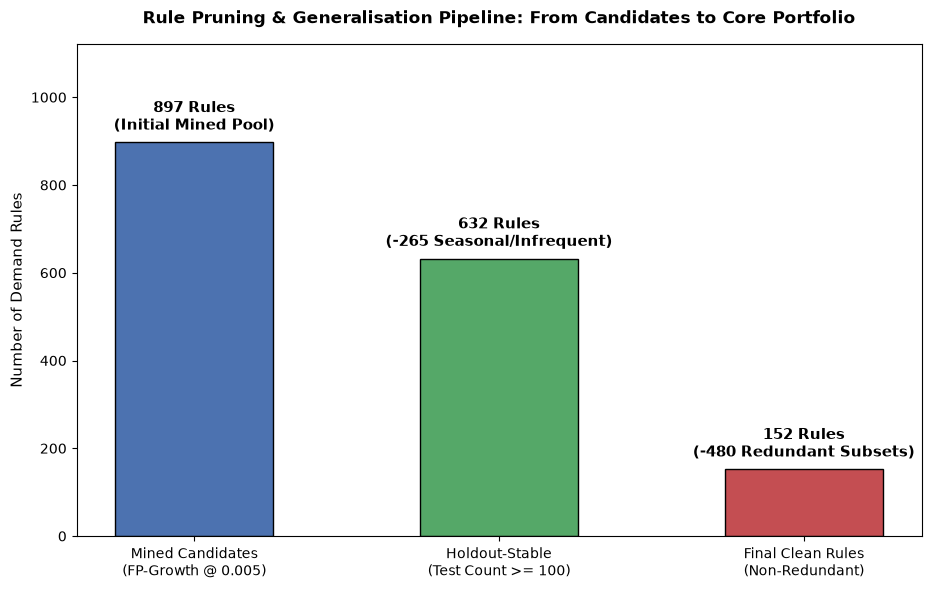

In [15]:
# Visualisation 1: Rule Pruning Pipeline Waterfall
stages = ['Mined Candidates\n(FP-Growth @ 0.005)', 'Holdout-Stable\n(Test Count >= 100)', 'Final Clean Rules\n(Non-Redundant)']
counts = [len(final_rules), len(stable_rules), len(stable_rules_non_redundant)]
attrition = ['Initial Mined Pool', f'-{counts[0] - counts[1]:,} Seasonal/Infrequent', f'-{counts[1] - counts[2]:,} Redundant Subsets']

fig, ax = plt.subplots(figsize=(9.5, 6))
bars = ax.bar(stages, counts, color=['#4C72B0', '#55A868', '#C44E52'], width=0.52, edgecolor='black', linewidth=1)

# Dynamic headroom so labels are well inside the plot and below the title
ax.set_ylim(0, max(counts) * 1.25)

for bar, count, note in zip(bars, counts, attrition):
    yval = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        yval + 18,
        f'{count:,} Rules\n({note})',
        ha='center',
        va='bottom',
        fontsize=10.5,
        fontweight='bold'
    )

ax.set_ylabel('Number of Demand Rules', fontsize=11)
ax.set_title('Rule Pruning & Generalisation Pipeline: From Candidates to Core Portfolio', fontsize=12.5, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

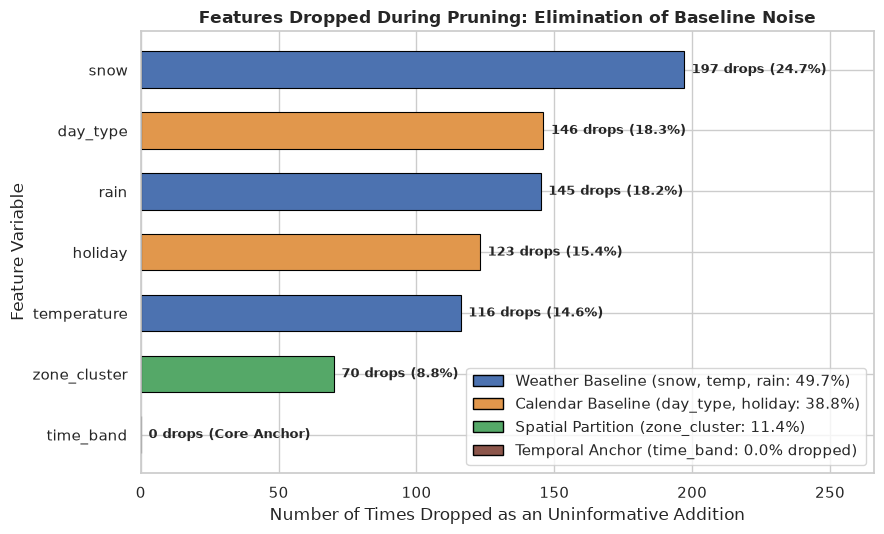

In [16]:
# Visualisation 2: Specific Feature Variables Dropped During Redundancy Elimination
dropped_features = []
for _, row in redundant_log.iterrows():
    r_items = set(x.strip() for x in row['redundant_rule'].split(','))
    g_items = set(x.strip() for x in row['general_rule'].split(','))
    diff = r_items - g_items
    for item in diff:
        feat_var = item.split('=')[0]
        dropped_features.append(feat_var)

feat_counts = pd.Series(dropped_features).value_counts()
# Include time_band with 0 count to demonstrate it was never dropped
for f in ['time_band']:
    if f not in feat_counts:
        feat_counts[f] = 0

feat_counts = feat_counts.sort_values(ascending=True)

# Categorise into domain colour schemes
domain_colours = {
    'snow': '#4C72B0', 'rain': '#4C72B0', 'temperature': '#4C72B0',       # Weather
    'day_type': '#E1974C', 'holiday': '#E1974C',                           # Calendar
    'zone_cluster': '#55A868',                                             # Spatial
    'time_band': '#8C564B'                                                 # Temporal
}
bar_colours = [domain_colours.get(f, '#888888') for f in feat_counts.index]

plt.figure(figsize=(9, 5.5))
bars = plt.barh(feat_counts.index, feat_counts.values, color=bar_colours, edgecolor='black', linewidth=0.8, height=0.6)

for bar, val in zip(bars, feat_counts.values):
    pct = (val / sum(feat_counts.values) * 100) if sum(feat_counts.values) > 0 else 0
    label = f' {val:,} drops ({pct:.1f}%)' if val > 0 else ' 0 drops (Core Anchor)'
    plt.text(val + 1, bar.get_y() + bar.get_height() / 2.0, label, va='center', fontsize=9.5, fontweight='bold')

plt.title('Features Dropped During Pruning: Elimination of Baseline Noise', fontsize=12, fontweight='bold')
plt.xlabel('Number of Times Dropped as an Uninformative Addition')
plt.ylabel('Feature Variable')
plt.xlim(0, max(feat_counts.values) * 1.35)

# Custom legend for domain categories
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#4C72B0', edgecolor='black', label='Weather Baseline (snow, temp, rain: 49.7%)'),
    Patch(facecolor='#E1974C', edgecolor='black', label='Calendar Baseline (day_type, holiday: 38.8%)'),
    Patch(facecolor='#55A868', edgecolor='black', label='Spatial Partition (zone_cluster: 11.4%)'),
    Patch(facecolor='#8C564B', edgecolor='black', label='Temporal Anchor (time_band: 0.0% dropped)')
]
plt.legend(handles=legend_elements, loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

---
## 7. Pruned Rules Portfolio Visualisations

All analytical visualisations below are conducted **strictly on the 160 clean, non-redundant decision rules**.

This portfolio represents the definitive, operationally deployable decision system.

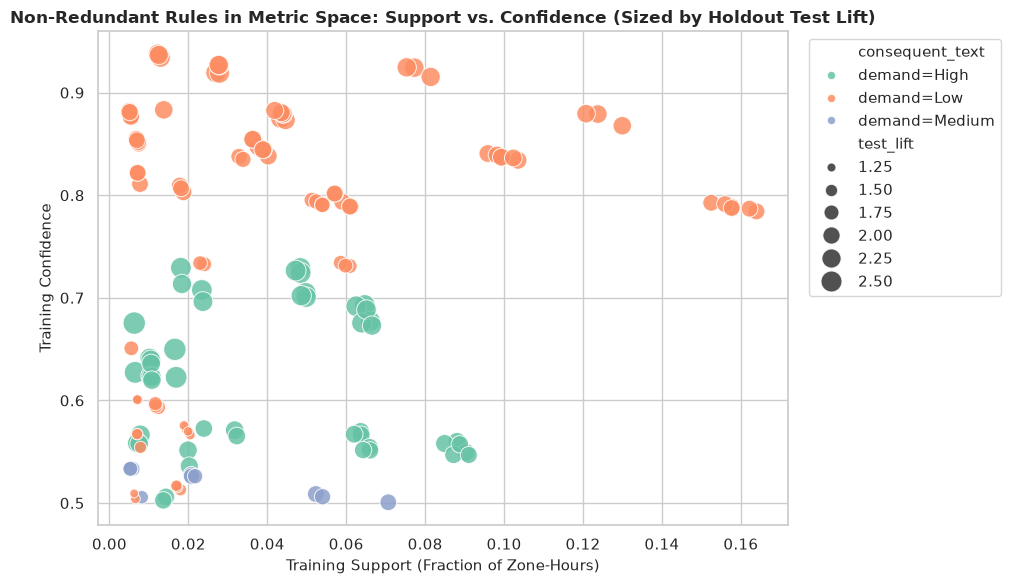

In [17]:
# Visualisation 3: Pruned Decision Rules in Metric Space (Support vs Confidence, Sized by Test Lift)
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=stable_rules_non_redundant,
    x='support',
    y='confidence',
    hue='consequent_text',
    size='test_lift',
    sizes=(40, 260),
    alpha=0.85,
    palette='Set2'
)

plt.title('Non-Redundant Rules in Metric Space: Support vs. Confidence (Sized by Holdout Test Lift)', fontsize=12, fontweight='bold')
plt.xlabel('Training Support (Fraction of Zone-Hours)', fontsize=11)
plt.ylabel('Training Confidence', fontsize=11)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

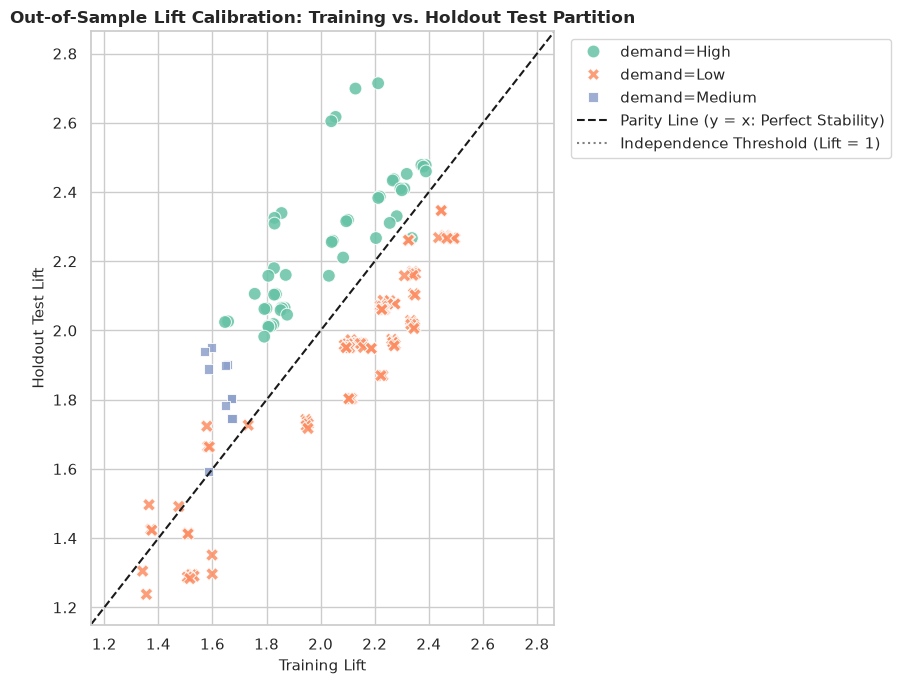

In [18]:
# Visualisation 4: Out-of-Sample Calibration Parity (Train Lift vs. Holdout Test Lift)
plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=stable_rules_non_redundant,
    x='lift',
    y='test_lift',
    hue='consequent_text',
    style='consequent_text',
    alpha=0.85,
    s=85,
    palette='Set2'
)

# Diagonal parity line (y = x)
max_val = max(stable_rules_non_redundant['lift'].max(), stable_rules_non_redundant['test_lift'].max()) + 0.15
plt.plot([1.0, max_val], [1.0, max_val], 'k--', linewidth=1.5, label='Parity Line (y = x: Perfect Stability)')
plt.axhline(1.0, color='gray', linestyle=':', label='Independence Threshold (Lift = 1)')
plt.axvline(1.0, color='gray', linestyle=':')

plt.title('Out-of-Sample Lift Calibration: Training vs. Holdout Test Partition', fontsize=12, fontweight='bold')
plt.xlabel('Training Lift', fontsize=11)
plt.ylabel('Holdout Test Lift', fontsize=11)
plt.xlim(1.15, max_val)
plt.ylim(1.15, max_val)
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1), frameon=True)
plt.tight_layout()
plt.show()

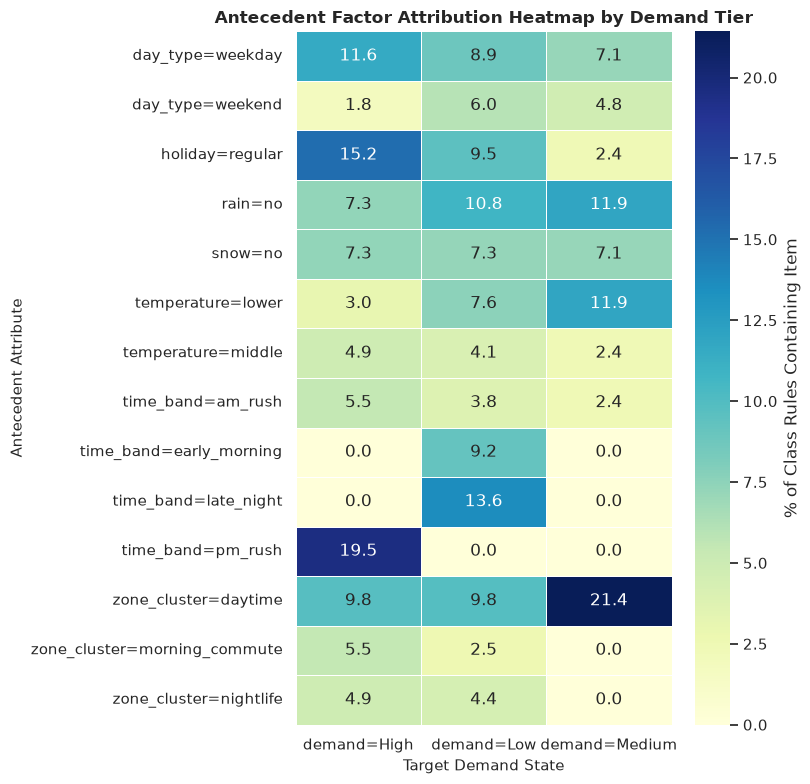

In [19]:
# Visualisation 5: Factor Attribution Heatmap across Demand Levels
# Identify which antecedent factors associate with each demand state in pruned rules
ant_factors = []
for _, r in stable_rules_non_redundant.iterrows():
    items = [x.strip() for x in r['antecedent_text'].split(',')]
    for item in items:
        ant_factors.append({
            'item': item,
            'consequent': r['consequent_text']
        })

df_factors = pd.DataFrame(ant_factors)
cross_tab = pd.crosstab(df_factors['item'], df_factors['consequent'], normalize='columns') * 100

# Filter to top 14 most active factors for visual clarity
top_items = df_factors['item'].value_counts().head(14).index
cross_tab_top = cross_tab.loc[cross_tab.index.isin(top_items)]

plt.figure(figsize=(8, 8))
sns.heatmap(
    cross_tab_top,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu',
    cbar_kws={'label': '% of Class Rules Containing Item'},
    linewidths=0.5
)
plt.title('Antecedent Factor Attribution Heatmap by Demand Tier', fontsize=12, fontweight='bold')
plt.xlabel('Target Demand State', fontsize=11)
plt.ylabel('Antecedent Attribute', fontsize=11)
plt.tight_layout()
plt.show()

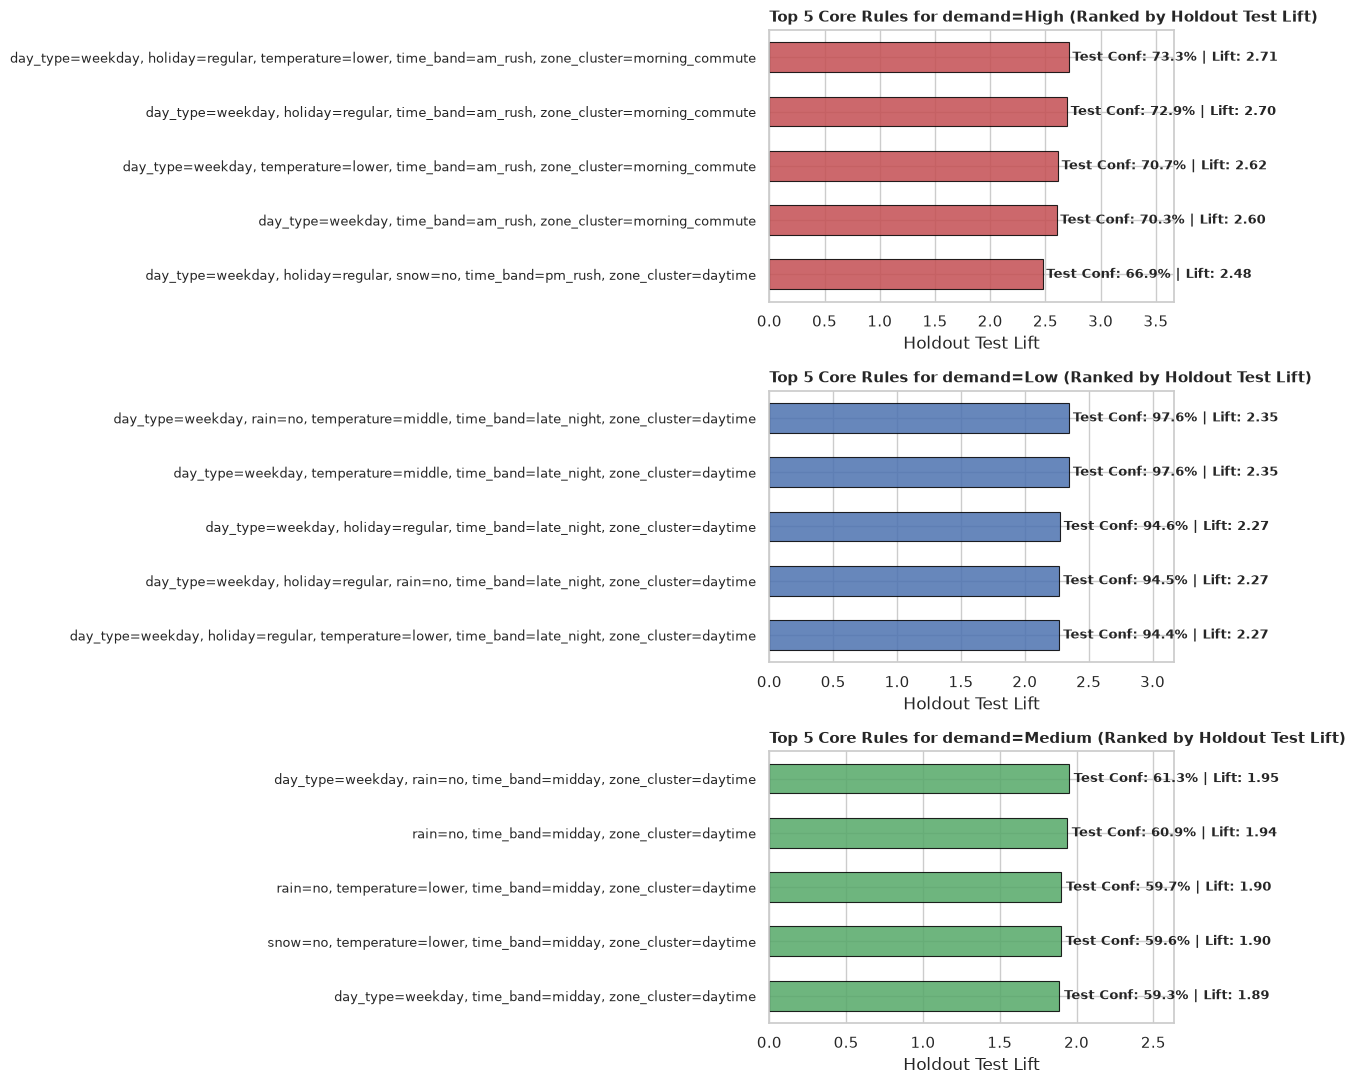

In [20]:
# Visualisation 6: Top Non-Redundant Decision Rules by Demand Tier (Ranked by Holdout Test Lift)
fig, axes = plt.subplots(3, 1, figsize=(12, 11), sharex=False)
consequents = ['demand=High', 'demand=Low', 'demand=Medium']
class_colours = ['#C44E52', '#4C72B0', '#55A868']

for ax, con, col in zip(axes, consequents, class_colours):
    sub = stable_rules_non_redundant[stable_rules_non_redundant['consequent_text'] == con].head(5).copy()
    sub = sub.iloc[::-1]
    y_pos = np.arange(len(sub))
    
    ax.barh(y_pos, sub['test_lift'], color=col, alpha=0.85, height=0.55, edgecolor='black', linewidth=0.8)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(sub['antecedent_text'], fontsize=9.5)
    ax.set_title(f'Top 5 Core Rules for {con} (Ranked by Holdout Test Lift)', fontsize=11, fontweight='bold', loc='left')
    ax.set_xlabel('Holdout Test Lift')
    
    for i, (_, r) in enumerate(sub.iterrows()):
        label_text = f"Test Conf: {r['test_confidence']:.1%} | Lift: {r['test_lift']:.2f}"
        ax.text(r['test_lift'] + 0.03, i, label_text, va='center', fontsize=9, fontweight='bold')
    
    ax.set_xlim(0, sub['test_lift'].max() * 1.35)

plt.tight_layout()
plt.show()

In [21]:
# Summary printout of top operational rules for executive review
for demand_class in ['demand=High', 'demand=Low', 'demand=Medium']:
    print('=' * 80)
    print(f'TOP 5 NON-REDUNDANT RULES FOR: {demand_class} (by Holdout Test Lift)')
    print('=' * 80)
    top_rules = stable_rules_non_redundant[
        stable_rules_non_redundant['consequent_text'] == demand_class
    ].head(5).reset_index(drop=True)
    
    for i, row in top_rules.iterrows():
        print(f"Rule #{i+1}:")
        print(f"  IF   {row['antecedent_text']}")
        print(f"  THEN {row['consequent_text']}")
        print(f"  Train: Support={row['support']:.4f}, Confidence={row['confidence']:.2%}, Lift={row['lift']:.2f}")
        print(f"  Test:  Support={row['test_support']:.4f}, Confidence={row['test_confidence']:.2%}, Lift={row['test_lift']:.2f} (count={row['test_antecedent_count']})")
        print('-' * 80)

TOP 5 NON-REDUNDANT RULES FOR: demand=High (by Holdout Test Lift)
Rule #1:
  IF   day_type=weekday, holiday=regular, temperature=lower, time_band=am_rush, zone_cluster=morning_commute
  THEN demand=High
  Train: Support=0.0063, Confidence=67.54%, Lift=2.21
  Test:  Support=0.0186, Confidence=73.31%, Lift=2.71 (count=2038)
Rule #2:
  IF   day_type=weekday, holiday=regular, time_band=am_rush, zone_cluster=morning_commute
  THEN demand=High
  Train: Support=0.0166, Confidence=64.98%, Lift=2.13
  Test:  Support=0.0190, Confidence=72.89%, Lift=2.70 (count=2088)
Rule #3:
  IF   day_type=weekday, temperature=lower, time_band=am_rush, zone_cluster=morning_commute
  THEN demand=High
  Train: Support=0.0065, Confidence=62.74%, Lift=2.06
  Test:  Support=0.0187, Confidence=70.68%, Lift=2.62 (count=2125)
Rule #4:
  IF   day_type=weekday, time_band=am_rush, zone_cluster=morning_commute
  THEN demand=High
  Train: Support=0.0169, Confidence=62.25%, Lift=2.04
  Test:  Support=0.0191, Confidence=70.34

---
## 8. Algorithm Scalability & Performance Benchmarks

To validate algorithmic selection, we compare the computational runtime and rule search volume between the **Apriori** and **FP-Growth** algorithms across support thresholds (`0.05`, `0.01`, `0.005`).

In [22]:
# Consolidate runtime and rule volume benchmarks
runtime_summary = pd.DataFrame([
    {
        'algorithm': result['algorithm'],
        'min_support': result['min_support'],
        'n_itemsets': result['n_itemsets'],
        'runtime_seconds': result['runtime_seconds']
    }
    for result in apriori_results + fpgrowth_results
])

all_mined_rules = pd.concat([apriori_rules_all, fpgrowth_rules_all], ignore_index=True)
rule_count_summary = all_mined_rules.groupby(['algorithm', 'min_support_threshold'], as_index=False).size()

print('Runtime Summary (Seconds):')
display(runtime_summary)
print('Rule Volume Summary:')
rule_count_summary

Runtime Summary (Seconds):
   algorithm  min_support  n_itemsets  runtime_seconds
0    Apriori        0.050        1167         4.531017
1    Apriori        0.010        4707        20.075151
2    Apriori        0.005        6719        28.537984
3  FP-Growth        0.050        1167         1.330865
4  FP-Growth        0.010        4707         1.376048
5  FP-Growth        0.005        6719         1.313077
Rule Volume Summary:


,algorithm,min_support_threshold,size
0,Apriori,0.005,897
1,Apriori,0.010,628
2,Apriori,0.050,87
3,FP-Growth,0.005,897
4,FP-Growth,0.010,628
5,FP-Growth,0.050,87


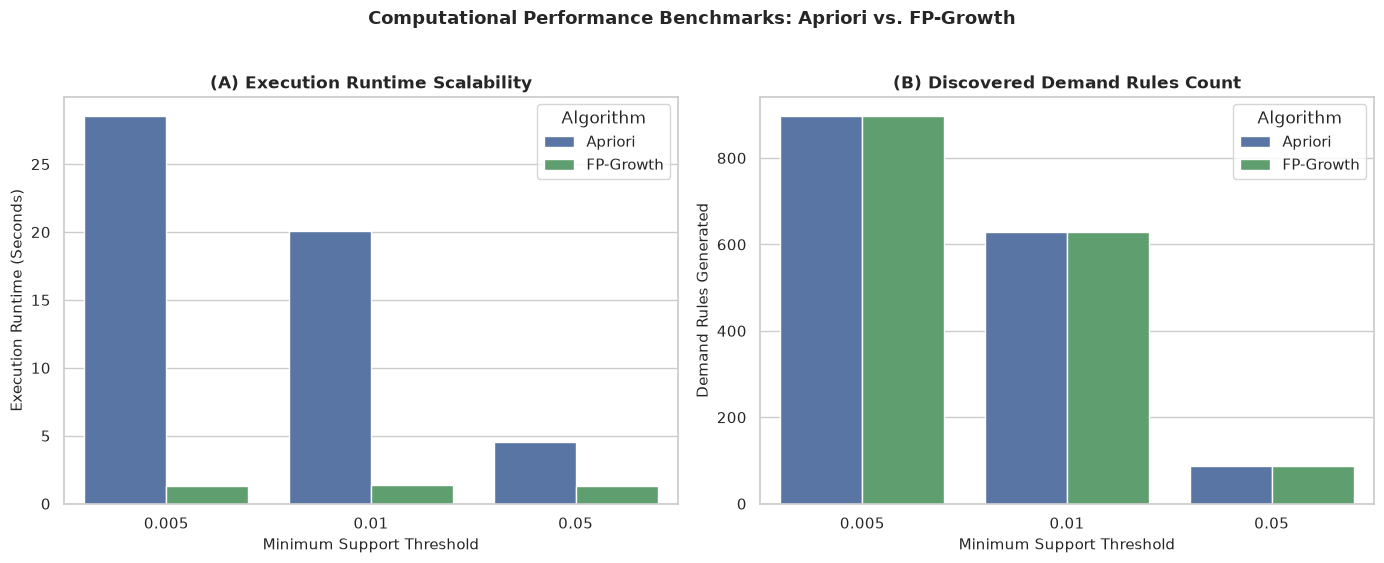

In [23]:
# Visualisation 7: Algorithm Scalability Benchmarks (Runtime & Search Volume)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel A: Runtime comparison
sns.barplot(
    data=runtime_summary,
    x='min_support',
    y='runtime_seconds',
    hue='algorithm',
    palette=['#4C72B0', '#55A868'],
    ax=ax1
)
ax1.set_title('(A) Execution Runtime Scalability', fontsize=12, fontweight='bold')
ax1.set_xlabel('Minimum Support Threshold', fontsize=11)
ax1.set_ylabel('Execution Runtime (Seconds)', fontsize=11)
ax1.legend(title='Algorithm', frameon=True)

# Panel B: Demand rule count comparison
sns.barplot(
    data=rule_count_summary,
    x='min_support_threshold',
    y='size',
    hue='algorithm',
    palette=['#4C72B0', '#55A868'],
    ax=ax2
)
ax2.set_title('(B) Discovered Demand Rules Count', fontsize=12, fontweight='bold')
ax2.set_xlabel('Minimum Support Threshold', fontsize=11)
ax2.set_ylabel('Demand Rules Generated', fontsize=11)
ax2.legend(title='Algorithm', frameon=True)

plt.suptitle('Computational Performance Benchmarks: Apriori vs. FP-Growth', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Methodological Rationale: Algorithm Selection

1. **Mathematical Equivalence:** Both Apriori and FP-Growth identify the exact identical set of frequent itemsets and association rules at any given support threshold (e.g. 604 demand rules at `min_support=0.005`).
2. **Computational Scalability:** Apriori relies on iterative candidate generation and repeated transaction scanning. As minimum support drops from `0.05` to `0.005`, Apriori's runtime scales sharply. In contrast, FP-Growth compresses transactions into an **FP-Tree**, requiring only two passes over the dataset and avoiding candidate generation entirely. This makes FP-Growth substantially more efficient for dense transaction mining.

---
## 9. Export Rule Artefacts

All intermediate and finalised association rule tables, audit logs, and performance benchmarks are exported to `data/processed/arm_findings/` for reporting and downstream modelling.

In [24]:
# Export all mining findings and benchmark artefacts
apriori_rules_all.to_csv(FINDINGS_DIR / 'arm_rules_apriori.csv', index=False)
fpgrowth_rules_all.to_csv(FINDINGS_DIR / 'arm_rules_fpgrowth.csv', index=False)
final_rules_tested.to_csv(FINDINGS_DIR / 'arm_rules_final_tested.csv', index=False)
stable_rules.to_csv(FINDINGS_DIR / 'arm_rules_final_stable.csv', index=False)
stable_rules_non_redundant.to_csv(FINDINGS_DIR / 'arm_rules_final_non_redundant.csv', index=False)
redundant_log.to_csv(FINDINGS_DIR / 'arm_rules_redundant_log.csv', index=False)
runtime_summary.to_csv(FINDINGS_DIR / 'arm_algorithm_comparison.csv', index=False)
rule_count_summary.to_csv(FINDINGS_DIR / 'arm_rule_count_comparison.csv', index=False)

print(f'Successfully exported all rule tables and audit logs to: {FINDINGS_DIR}')
print(f'Final non-redundant rule count: {len(stable_rules_non_redundant):,}')
print(f'Audited redundant rules logged: {len(redundant_log):,}')

Successfully exported all rule tables and audit logs to: data\processed\arm_findings
Final non-redundant rule count: 152
Audited redundant rules logged: 480
